# Lab 7: ANOVA I
## With Lake Data

------



Lab TA: Lee Ochs

## Lab Objectives:

1.	One way ANOVA
2.	Planned contrast
3.	More data frame manipulation (data delting, binding, merging, etc)

In [1]:
#load the correct environment/kernel (python 3 ipykernel)
#mine uses the base enviornment 
#if package does not load correctly, close notebook, type "conda activate base" in ur terminal, then type "jupyter notebook"
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#create the data
data = {
    "A": [5, 8, 1, 2, 3, 5, 2, 2, 4, 5],
    "B": np.random.randint(50,61,10),
    "C": np.random.randint(20,25,10),
    "D": np.random.randint(20,28,10),
}
df = pd.DataFrame(data)

df.head(10)
#this is a wide format, each column is a different group
#when we want to easily plot by variables (A, B, C, D) or some statistic analysis by groups, we convert to long format

,A,B,C,D
0,5,54,20,24
1,8,58,21,22
2,1,52,23,25
3,2,57,21,22
4,3,54,24,23
5,5,51,22,20
6,2,53,20,25
7,2,57,22,25
8,4,52,24,24
9,5,51,21,23


In [6]:
#melt into long format for easy analysis/plotting
# Melt into long format for ANOVA
df_long = df.melt(var_name="Site", value_name="Concentration")

#this will take each column name and make it a value in the new column "Site"
#the values in each column will be stacked into the new column "Concentration"

df_long.head(20)

,Site,Concentration
0,A,5
1,A,8
2,A,1
3,A,2
4,A,3
5,A,5
6,A,2
7,A,2
8,A,4
9,A,5


C:\Users\noahr\AppData\Local\Temp\ipykernel_23356\2683346263.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df_long,x="Site", y="Concentration", palette="Set2")


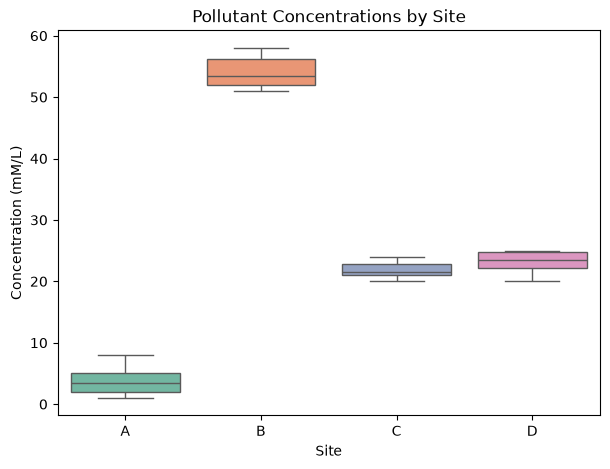

In [7]:
#Practise do a box plot and then try violin plot (sns.violinplot)
plt.figure(figsize=(7,5))
sns.boxplot(data = df_long,x="Site", y="Concentration", palette="Set2")
#sns.violinplot(data = df_long,x="Site", y="Concentration", palette="Accent", inner="box")
plt.title("Pollutant Concentrations by Site")
plt.suptitle("")
plt.xlabel("Site")
plt.ylabel("Concentration (mM/L)")
plt.show()

#practise, go to this website https://www.practicalpythonfordatascience.com/ap_seaborn_palette
#find the color palette you like and change the palette above


In labs before, for time series plot, we plot multple times for each variables
- we can just melt them into long format and plot all at once
- palette will automatically assign colors to each variable
- more predefined color palettes https://www.practicalpythonfordatascience.com/ap_seaborn_palette

C:\Users\noahr\AppData\Local\Temp\ipykernel_23356\154829123.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


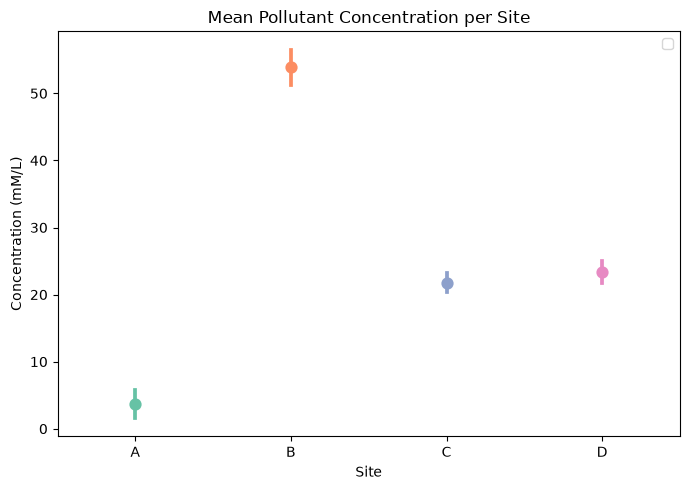

In [8]:
#practise fill in the code below
# Plot mean ± standard deviation (equivalent to MATLAB's errorbar)
plt.figure(figsize=(7,5))
sns.pointplot(data=df_long, x="Site", y="Concentration", errorbar=('sd'),hue='Site', palette="Set2")
plt.title("Mean Pollutant Concentration per Site")
plt.xlabel("Site")
plt.ylabel("Concentration (mM/L)")
plt.legend()
plt.tight_layout()
plt.show()

#hue determine the color coding, you can based on any category variable，in here we have sites
#https://seaborn.pydata.org/generated/seaborn.pointplot.html

Steps
1. One way anova (null hypothesis)
2. then determine if post hoc or a prior

In [22]:

#One-way ANOVA using statsmodels
#for the null hypothesis:
#the means of all site are equal

#we are still using the ols from statsmodels, ols stands for ordinary least squares, it is used in many linear models and anova is one of them
model = ols("Concentration ~ Site", data=df_long).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

anova_table


,sum_sq,df,F,PR(>F)
Site,13002.075,3.0,1078.264686,2.731406e-35
Residual,144.700,36.0,NaN,NaN


In [9]:
#now lets do post hoc analysis
#we will use the function pairwise_tukeyhsd from statsmodels
tukey = pairwise_tukeyhsd(endog=df_long['Concentration'], #endogenous variables. i.e., the data values, the measurements you try to explain/compare
                          groups=df_long['Site'], 
                          alpha=0.05) #significance level
print(tukey)

type(tukey)
#tukey is a statsmodels object

 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
     A      B     50.2    0.0  47.7853  52.6147   True
     A      C     18.1    0.0  15.6853  20.5147   True
     A      D     19.6    0.0  17.1853  22.0147   True
     B      C    -32.1    0.0 -34.5147 -29.6853   True
     B      D    -30.6    0.0 -33.0147 -28.1853   True
     C      D      1.5 0.3524  -0.9147   3.9147  False
------------------------------------------------------


statsmodels.sandbox.stats.multicomp.TukeyHSDResults

In [10]:
tukey_summary = tukey.summary()
#we can extract the data from the summary and make it a dataframe for easy reading
tukey_data = pd.DataFrame(data=tukey_summary.data[1:], #take the data rows
                          columns=tukey_summary.data[0] #take the header row, the names of the data
                          )
print(tukey_data)

#What do you think of C and D? They are not statistically different from each other but both are different from A and B.


  group1 group2  meandiff   p-adj    lower    upper  reject
0      A      B      50.2  0.0000  47.7853  52.6147    True
1      A      C      18.1  0.0000  15.6853  20.5147    True
2      A      D      19.6  0.0000  17.1853  22.0147    True
3      B      C     -32.1  0.0000 -34.5147 -29.6853    True
4      B      D     -30.6  0.0000 -33.0147 -28.1853    True
5      C      D       1.5  0.3524  -0.9147   3.9147   False


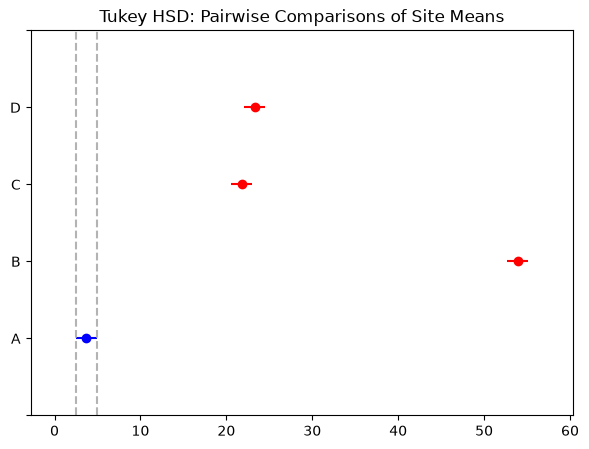

In [11]:
# Plot the Tukey HSD results
#tukey has a built-in plot function
# choose one comparison to plot
#A will be used as reference
tukey.plot_simultaneous(comparison_name='A', figsize=(7,5))
plt.title("Tukey HSD: Pairwise Comparisons of Site Means")
plt.show()


#the horizontal lines are the confidence intervals, not the raw value. Since we used p 0.05, the confidence level is 95%

Now lets try planned contrasts (a priori)
Key part is to calculate the F value and then get the p: 


$$
F = \frac{SS_{\text{contrast}}}{MSE}
$$

where:

- $SS_{\text{contrast}} = \dfrac{\left( \sum_{i} w_{i} \overline{y}_{i} \right)^2}{\sum_{i} \dfrac{w_i^2}{n_i}}$
    - $w_i$ = contrast weight for group $i$
    - $\overline{y}_i$ = mean of group $i$
    - $n_i$ = sample size of group $i$
- $MSE$ is the mean square error from the ANOVA residuals.

In [23]:
#we can calculate the MSE from the anova table
anova_table
#we need to get the sum of squares for residuals, and the degree of freedom for residuals
#we can access the value usinng loc,
#for example for the sum of squares, .loc uses names,
#iloc use index number, I prefer loc since it is more explicit
anova_table.loc['Residual', 'sum_sq']

#practise, get the degree of freedom for residuals and calculate MSE
ss_residual = anova_table.loc['Residual', 'sum_sq']
dof_residual = anova_table.loc['Residual', 'df']
mse = ss_residual / dof_residual
mse


np.float64(4.019444444444445)

Now lets get the contrast SS (sum of square)
- Mean for each group
- Weighted based on the contrast 
- Sum them

In [15]:
#df_long.mean()#however, that calculate mean of all
groupmeans = df_long.groupby('Site').mean()

groupmeans

,Concentration
Site,
A,3.7
B,53.9
C,21.8
D,23.3


In [16]:
#lets test the first contrast which is 0, 2, -1, -1, for A, B, C, D

#lets create a data frame for all contrasts the merge them
#lets practise with one contrast
contrasts = pd.DataFrame({
    'Site': ['A', 'B', 'C', 'D'],
    'contrast1': [0, 2, -1, -1]
})

#now we can merge based on site
plannedcontrast=pd.merge(groupmeans, contrasts, on = 'Site')

plannedcontrast

#practise, how about you add all the contrasts from the slides

,Site,Concentration,contrast1
0,A,3.7,0
1,B,53.9,2
2,C,21.8,-1
3,D,23.3,-1


In [18]:
#it is easier to calculate the contrast value now
contrast1_val = (plannedcontrast['Concentration'] * plannedcontrast['contrast1']).sum()
contrast1_val

np.float64(62.7)

In [19]:
n= 10
SScontrast1= (contrast1_val**2) / ((plannedcontrast['contrast1']**2).sum()/n)

In [24]:
F_contrast1 = SScontrast1 / mse

print (F_contrast1)
from scipy.stats import f
p_value = 1 - f.cdf(F_contrast1, 1, dof_residual)
p_value

1630.1133379405667


np.float64(0.0)